In [11]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Python: ",sys.executable)
print("Pandas version: ",pd.__version__)
print("Setup successful!")

Python:  c:\Users\Nanmiwop\AppData\Local\Programs\Python\Python314\python.exe
Pandas version:  3.1.0
Setup successful!


In [2]:
import pandas as pd

df=pd.read_csv("supermarket_sales - Sheet1.csv")
df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3


In [13]:
df.shape


(1000, 17)

In [14]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1000 non-null   str    
 1   Branch                   1000 non-null   str    
 2   City                     1000 non-null   str    
 3   Customer type            1000 non-null   str    
 4   Gender                   1000 non-null   str    
 5   Product line             1000 non-null   str    
 6   Unit price               1000 non-null   float64
 7   Quantity                 1000 non-null   int64  
 8   Tax 5%                   1000 non-null   float64
 9   Total                    1000 non-null   float64
 10  Date                     1000 non-null   str    
 11  Time                     1000 non-null   str    
 12  Payment                  1000 non-null   str    
 13  cogs                     1000 non-null   float64
 14  gross margin percentage  1000 non-nu

In [15]:
df.isnull().sum()

Invoice ID                 0
Branch                     0
City                       0
Customer type              0
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Total                      0
Date                       0
Time                       0
Payment                    0
cogs                       0
gross margin percentage    0
gross income               0
Rating                     0
dtype: int64

In [16]:
df.duplicated().sum()

np.int64(0)

In [17]:
df.columns

Index(['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender',
       'Product line', 'Unit price', 'Quantity', 'Tax 5%', 'Total', 'Date',
       'Time', 'Payment', 'cogs', 'gross margin percentage', 'gross income',
       'Rating'],
      dtype='str')

In [6]:
# 1. Overall sales summary
print("Total revenue:", df["Total"].sum())
print("Average transaction value:", df["Total"].mean())
print("Total units sold:", df["Quantity"].sum())
print("Number of transactions:", df["Invoice ID"].nunique())

# 2. Revenue by product line
product_sales = df.groupby("Product line")["Total"].sum().sort_values(ascending=False)
print("\nRevenue by product line:")
print(product_sales)

# 3. Revenue by branch
branch_sales = df.groupby("Branch")["Total"].sum().sort_values(ascending=False)
print("\nRevenue by branch:")
print(branch_sales)

# 4. Quantity sold by product line
product_quantity = df.groupby("Product line")["Quantity"].sum().sort_values(ascending=False)
print("\nQuantity sold by product line:")
print(product_quantity)

# 5. Most frequently used payment method
payment_counts = df["Payment"].value_counts()
print("\nPayment method counts:")
print(payment_counts)

Total revenue: 322966.749
Average transaction value: 322.966749
Total units sold: 5510
Number of transactions: 1000

Revenue by product line:
Product line
Food and beverages        56144.8440
Sports and travel         55122.8265
Electronic accessories    54337.5315
Fashion accessories       54305.8950
Home and lifestyle        53861.9130
Health and beauty         49193.7390
Name: Total, dtype: float64

Revenue by branch:
Branch
C    110568.7065
A    106200.3705
B    106197.6720
Name: Total, dtype: float64

Quantity sold by product line:
Product line
Electronic accessories    971
Food and beverages        952
Sports and travel         920
Home and lifestyle        911
Fashion accessories       902
Health and beauty         854
Name: Quantity, dtype: int64

Payment method counts:
Payment
Ewallet        345
Cash           344
Credit card    311
Name: count, dtype: int64


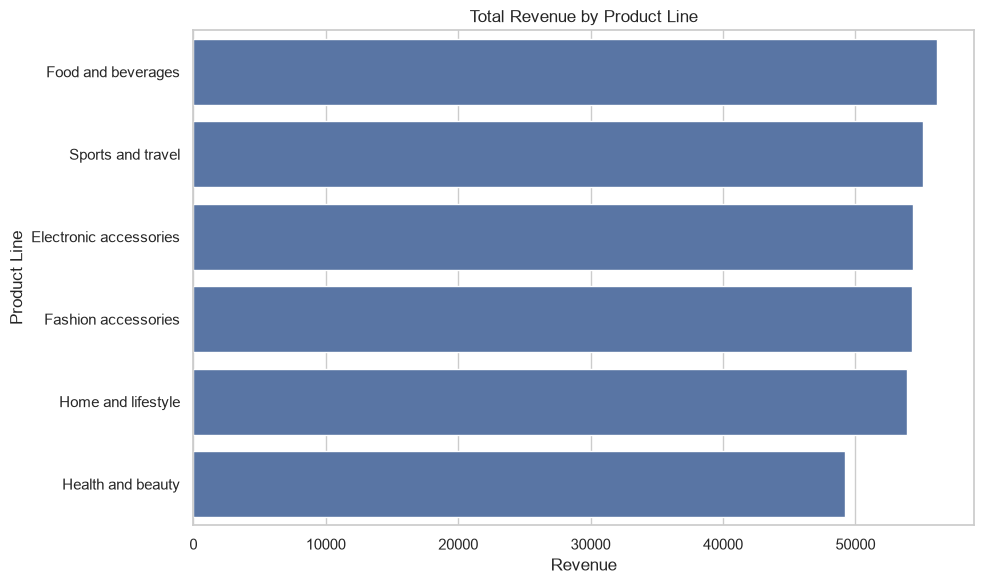

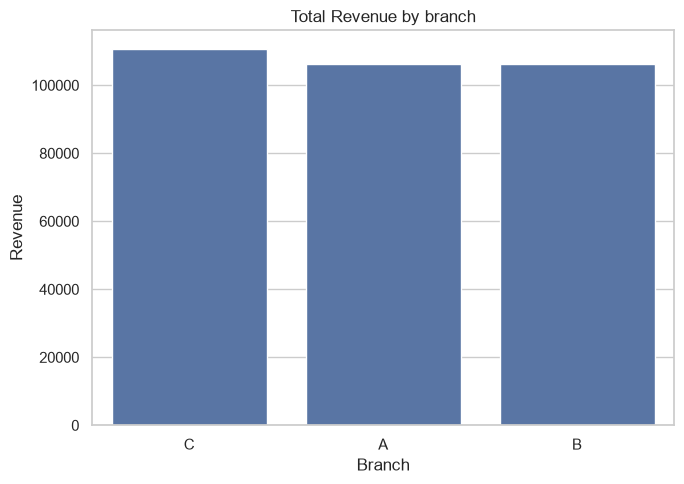

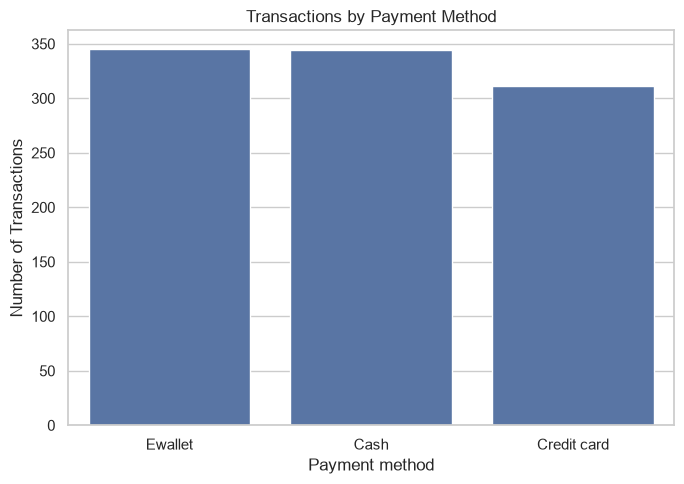

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Revenue by product line
plt.figure(figsize=(10,6))
sns.barplot(x=product_sales.values,y=product_sales.index)
plt.title("Total Revenue by Product Line")
plt.xlabel("Revenue")
plt.ylabel("Product Line")
plt.tight_layout()
plt.show()

# Revenue by branch
plt.figure(figsize=(7,5))
sns.barplot(x=branch_sales.index,y=branch_sales.values)
plt.title("Total Revenue by branch")
plt.xlabel("Branch")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

# Payment method preferences
plt.figure(figsize=(7,5))
sns.barplot(x=payment_counts.index,y=payment_counts.values)
plt.title("Transactions by Payment Method")
plt.xlabel("Payment method")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()



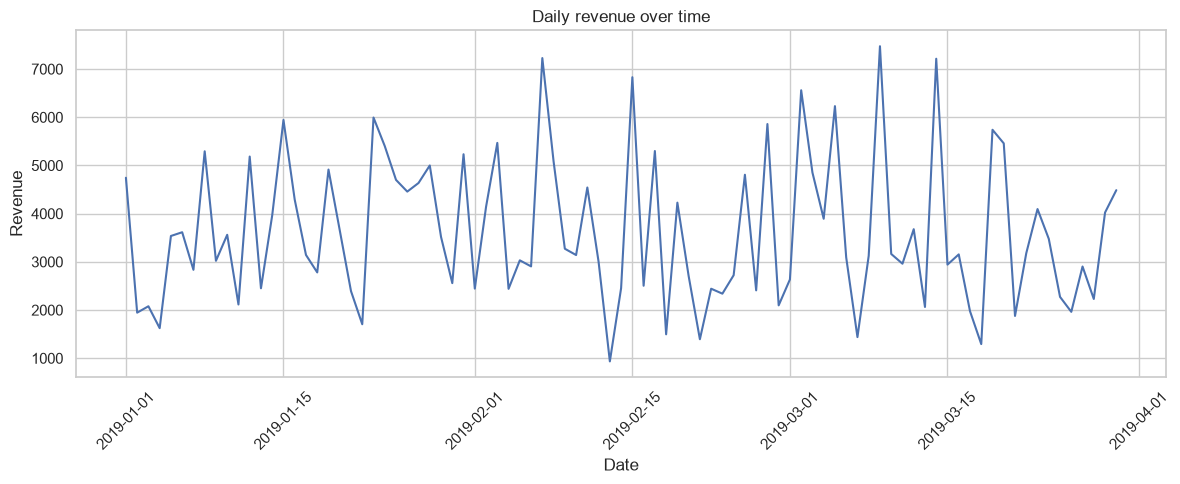

In [25]:
# Convert date from text to a timeline format
df["Date"]=pd.to_datetime(df["Date"])

# Calculate daily revenue
daily_sales=df.groupby("Date")["Total"].sum().sort_index()

# Plot daily revenue
plt.figure(figsize=(12,5))
plt.plot(daily_sales.index,daily_sales.values)
plt.title("Daily revenue over time")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



In [26]:
print(df.dtypes)

Invoice ID                            str
Branch                                str
City                                  str
Customer type                         str
Gender                                str
Product line                          str
Unit price                        float64
Quantity                            int64
Tax 5%                            float64
Total                             float64
Date                       datetime64[us]
Time                                  str
Payment                               str
cogs                              float64
gross margin percentage           float64
gross income                      float64
Rating                            float64
dtype: object


In [3]:
print("First date:", df["Date"].min())
print("Last date:", df["Date"].max())
print("Number of distinct dates:", df["Date"].nunique())

First date: 1/1/2019
Last date: 3/9/2019
Number of distinct dates: 89


In [4]:
print(df["Payment"].value_counts())

Payment
Ewallet        345
Cash           344
Credit card    311
Name: count, dtype: int64


In [7]:
print("Revenue by product line: ")
print(product_sales.round(2))

print("\nRevenue by branch: ")
print(branch_sales.round(2))

print("\n Transactions by payment method: ")
print(payment_counts)

print(
    "\nE-wallet leads cash by: ",
    payment_counts["Ewallet"]-payment_counts["Cash"],
    "transactions"
)

Revenue by product line: 
Product line
Food and beverages        56144.84
Sports and travel         55122.83
Electronic accessories    54337.53
Fashion accessories       54305.90
Home and lifestyle        53861.91
Health and beauty         49193.74
Name: Total, dtype: float64

Revenue by branch: 
Branch
C    110568.71
A    106200.37
B    106197.67
Name: Total, dtype: float64

 Transactions by payment method: 
Payment
Ewallet        345
Cash           344
Credit card    311
Name: count, dtype: int64

E-wallet leads cash by:  1 transactions


In [6]:
#Revenue by customer type
print("Revenue by customer type: ")
print(df.groupby("Customer type")["Total"].sum().round(2))

#Revenue by gender
print("\nRevenue by gender: ")
print(df.groupby("Gender")["Total"].sum().round(2))

#Average customer rating by product line
print("\nAverage rating by product line: ")
print(
    df.groupby("Product line")["Rating"]
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

#Summary statistice for numerical columns
print("\nNumerical summary: ")
print(df[["Unit price","Quantity","Total","Rating"]].describe().round(2))


#data types
print("Date data type: ",df["Date"].dtype)
print("Missing values:",df.isnull().sum())
print("Duplicate rows: ",df.duplicated().sum())


Revenue by customer type: 
Customer type
Member    164223.44
Normal    158743.30
Name: Total, dtype: float64

Revenue by gender: 
Gender
Female    167882.92
Male      155083.82
Name: Total, dtype: float64

Average rating by product line: 
Product line
Food and beverages        7.11
Fashion accessories       7.03
Health and beauty         7.00
Electronic accessories    6.92
Sports and travel         6.92
Home and lifestyle        6.84
Name: Rating, dtype: float64

Numerical summary: 
       Unit price  Quantity    Total   Rating
count     1000.00   1000.00  1000.00  1000.00
mean        55.67      5.51   322.97     6.97
std         26.49      2.92   245.89     1.72
min         10.08      1.00    10.68     4.00
25%         32.88      3.00   124.42     5.50
50%         55.23      5.00   253.85     7.00
75%         77.94      8.00   471.35     8.50
max         99.96     10.00  1042.65    10.00
Date data type:  str
Missing values: Invoice ID                 0
Branch                     0
Cit

In [7]:
df["Date"] = pd.to_datetime(df["Date"], format="%m/%d/%Y")

print("Date data type:", df["Date"].dtype)
print("First date:", df["Date"].min().strftime("%d %b %Y"))
print("Last date:", df["Date"].max().strftime("%d %b %Y"))
print("Distinct dates:", df["Date"].nunique())

Date data type: datetime64[us]
First date: 01 Jan 2019
Last date: 30 Mar 2019
Distinct dates: 89
